In [1]:
!pip install -q datasets

import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import random, json, os, time, copy
import matplotlib.pyplot as plt, pandas as pd
from datasets import load_dataset
from sklearn.metrics import roc_auc_score
from google.colab import drive

drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/fair_skin'
os.makedirs(OUT, exist_ok=True)
torch.set_num_threads(os.cpu_count())

Mounted at /content/drive


In [2]:
ds = load_dataset('marmal88/skin_cancer')
IMG = 64

meta, X, seen = [], [], set()
for split in ['train', 'validation', 'test']:
    d = ds[split]
    m = d.remove_columns('image').to_pandas()
    keep = [i for i, iid in enumerate(m['image_id']) if iid not in seen]
    seen.update(m['image_id'].iloc[keep])
    meta.append(m.iloc[keep])
    for ex in d.select(keep):
        X.append(np.asarray(ex['image'].convert('RGB').resize((IMG, IMG))))
meta = pd.concat(meta, ignore_index=True)
X = np.stack(X)
print('rows in HF splits:', sum(len(ds[s]) for s in ds), '| unique images:', len(meta))
print(meta['dx'].value_counts())

README.md:   0%|          | 0.00/3.24k [00:00<?, ?B/s]

data/train-00000-of-00005-7eed077f2f8e6d(…): reconstructing file:   0%|          |  0.00B /  521MB            

data/train-00000-of-00005-7eed077f2f8e6d(…): downloading bytes:           |  0.00B            

data/train-00001-of-00005-50ba64fd20294b(…): reconstructing file:   0%|          |  0.00B /  525MB            

data/train-00001-of-00005-50ba64fd20294b(…): downloading bytes:           |  0.00B            

data/train-00002-of-00005-36c02a25cbdd54(…): reconstructing file:   0%|          |  0.00B /  527MB            

... (11 outputs left out)

Generating train split:   0%|          | 0/9577 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2492 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1285 [00:00<?, ? examples/s]

rows in HF splits: 13354 | unique images: 10015
dx
melanocytic_Nevi                 6705
melanoma                         1113
benign_keratosis-like_lesions    1099
basal_cell_carcinoma              514
actinic_keratoses                 327
vascular_lesions                  142
dermatofibroma                    115
Name: count, dtype: int64


In [3]:
MALIGNANT = {'mel', 'bcc', 'akiec', 'melanoma', 'basal_cell_carcinoma', 'actinic_keratoses'}
meta['y'] = meta['dx'].isin(MALIGNANT).astype(int)
ok = (meta['sex'].isin(['male', 'female']) & meta['age'].notna()).values
meta, X = meta[ok].reset_index(drop=True), X[ok]
meta['age_group'] = np.where(meta['age'] >= 60, '60plus', 'under60')
print('images:', len(meta), '| malignant rate:', round(meta['y'].mean(), 3))
print(pd.crosstab([meta['sex'], meta['age_group']], meta['y']))

# split by lesion so no lesion appears in both train and test
rng = np.random.default_rng(0)
lesions = meta['lesion_id'].unique()
test_les = set(rng.choice(lesions, size=int(0.25 * len(lesions)), replace=False))
te = meta['lesion_id'].isin(test_les).values
trn = ~te

def to_t(A):
    return torch.from_numpy((A.astype(np.float32) / 255 - 0.5) / 0.5).permute(0, 3, 1, 2).contiguous()

Xtr_t, Xte_t = to_t(X[trn]), to_t(X[te])
ytr, yte = meta['y'].values[trn], meta['y'].values[te]
ytr_t = torch.tensor(ytr, dtype=torch.float32)
GROUPS = {'sex': (meta['sex'].values[trn], meta['sex'].values[te]),
          'age': (meta['age_group'].values[trn], meta['age_group'].values[te])}

# weights for group-balanced reweighting: each (sex, age, label) cell counts equally
cell = pd.Series([f'{s}_{a}_{y}' for s, a, y in zip(GROUPS['sex'][0], GROUPS['age'][0], ytr)])
W = (1.0 / cell.map(cell.value_counts())).values
W = W / W.mean()
print('train:', len(ytr), '| test:', len(yte))

images: 9948 | malignant rate: 0.196
y                    0    1
sex    age_group           
female 60plus      823  434
       under60    2998  293
male   60plus     1458  884
       under60    2717  341
train: 7505 | test: 2443


In [4]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

def make_model():
    def block(i, o):
        return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False),
                             nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
    return nn.Sequential(block(3, 32), block(32, 64), block(64, 128),
                         nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, 1))

def train(seed, weights=None, epochs=15):
    set_seed(seed); model = make_model()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    w = torch.ones(len(ytr_t)) if weights is None else torch.tensor(weights, dtype=torch.float32)
    g = torch.Generator().manual_seed(seed)
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(Xtr_t, ytr_t, w),
                                         batch_size=64, shuffle=True, generator=g)
    for ep in range(epochs):
        model.train()
        for x, y, wb in loader:
            if torch.rand(1) < 0.5: x = x.flip(3)   # random flips (dermoscopy has no orientation)
            if torch.rand(1) < 0.5: x = x.flip(2)
            loss = (F.binary_cross_entropy_with_logits(model(x).squeeze(1), y,
                                                       reduction='none') * wb).mean()
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    return model

@torch.no_grad()
def predict(model, Xt):
    model.eval()
    return torch.cat([torch.sigmoid(model(Xt[i:i+512]).squeeze(1))
                      for i in range(0, len(Xt), 512)]).numpy()

@torch.no_grad()
def recalibrate_bn(model, Xt):
    m = copy.deepcopy(model)
    for mod in m.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.reset_running_stats(); mod.momentum = None
    m.train()
    for i in range(0, len(Xt), 256):
        m(Xt[i:i+256])
    m.eval()
    return m

def group_bn_predict(model, gtr, gte):
    p = np.zeros(len(yte))
    for k in np.unique(gte):
        mk = recalibrate_bn(model, Xtr_t[torch.from_numpy(gtr == k)])
        idx = gte == k
        p[idx] = predict(mk, Xte_t[torch.from_numpy(idx)])
    return p

def fairness(p, g):
    auc = roc_auc_score(yte, p)
    aucs = {k: roc_auc_score(yte[g == k], p[g == k]) for k in np.unique(g)}
    es = auc / (1 + sum(abs(a - auc) for a in aucs.values()))   # equity-scaled AUC
    return auc, aucs, max(aucs.values()) - min(aucs.values()), es

In [5]:
t = time.time(); m = train(0, epochs=1)
print(f'1 epoch: {time.time()-t:.0f}s | test AUC after 1 epoch: {roc_auc_score(yte, predict(m, Xte_t)):.3f}')

1 epoch: 82s | test AUC after 1 epoch: 0.806


In [6]:
path = f'{OUT}/results.json'
results = json.load(open(path)) if os.path.exists(path) else []
done_seeds = {r['seed'] for r in results}

for seed in [0, 1]:
    if seed in done_seeds: continue
    t = time.time()
    m_erm = train(seed, epochs=10)
    m_rw = train(seed, weights=W, epochs=10)
    m_all = recalibrate_bn(m_erm, Xtr_t)
    for attr, (gtr, gte) in GROUPS.items():
        preds = {'ERM': predict(m_erm, Xte_t),
                 'Reweight': predict(m_rw, Xte_t),
                 'ERM + recal (all)': predict(m_all, Xte_t),
                 'ERM + group BN': group_bn_predict(m_erm, gtr, gte)}
        for method, p in preds.items():
            auc, aucs, gap, es = fairness(p, gte)
            results.append(dict(seed=seed, attr=attr, method=method, auc=auc, gap=gap, es_auc=es,
                                **{f'g_{k}': v for k, v in aucs.items()}))
            print(f"seed={seed} {attr:3s} {method:18s} AUC={auc:.3f} gap={gap:.3f} ES-AUC={es:.3f}")
    json.dump(results, open(path, 'w'))
    print(f'seed {seed} done in {time.time()-t:.0f}s')

seed=0 sex ERM                AUC=0.868 gap=0.004 ES-AUC=0.862
seed=0 sex Reweight           AUC=0.856 gap=0.037 ES-AUC=0.826
seed=0 sex ERM + recal (all)  AUC=0.868 gap=0.001 ES-AUC=0.863
seed=0 sex ERM + group BN     AUC=0.867 gap=0.003 ES-AUC=0.864
seed=0 age ERM                AUC=0.868 gap=0.035 ES-AUC=0.822
seed=0 age Reweight           AUC=0.856 gap=0.022 ES-AUC=0.815
seed=0 age ERM + recal (all)  AUC=0.868 gap=0.033 ES-AUC=0.822
seed=0 age ERM + group BN     AUC=0.834 gap=0.065 ES-AUC=0.783
seed 0 done in 1689s
seed=1 sex ERM                AUC=0.877 gap=0.013 ES-AUC=0.866
seed=1 sex Reweight           AUC=0.866 gap=0.029 ES-AUC=0.842
seed=1 sex ERM + recal (all)  AUC=0.875 gap=0.007 ES-AUC=0.869
seed=1 sex ERM + group BN     AUC=0.874 gap=0.004 ES-AUC=0.870
seed=1 age ERM                AUC=0.877 gap=0.036 ES-AUC=0.835
seed=1 age Reweight           AUC=0.866 gap=0.032 ES-AUC=0.825
seed=1 age ERM + recal (all)  AUC=0.875 gap=0.037 ES-AUC=0.834
seed=1 age ERM + group BN     AUC=

                          auc    gap  es_auc
attr method                                 
age  ERM                0.872  0.035   0.829
     ERM + group BN     0.837  0.069   0.783
     ERM + recal (all)  0.871  0.035   0.828
     Reweight           0.861  0.027   0.820
sex  ERM                0.872  0.009   0.864
     ERM + group BN     0.870  0.004   0.867
     ERM + recal (all)  0.871  0.004   0.866
     Reweight           0.861  0.033   0.834


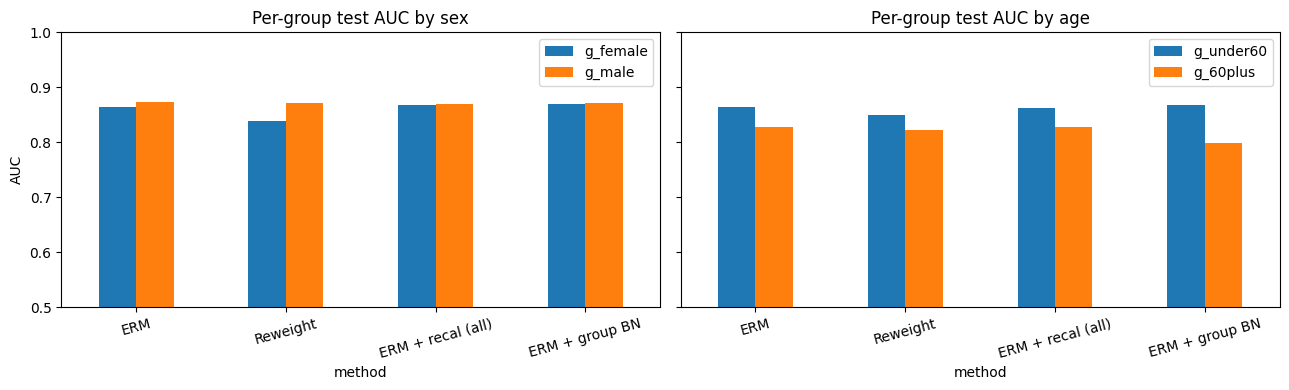

In [7]:
df = pd.DataFrame(results)
order = ['ERM', 'Reweight', 'ERM + recal (all)', 'ERM + group BN']
summ = df.groupby(['attr', 'method'])[['auc', 'gap', 'es_auc']].mean().round(3)
print(summ); summ.to_csv(f'{OUT}/summary.csv')

fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for j, (attr, cols) in enumerate([('sex', ['g_female', 'g_male']),
                                  ('age', ['g_under60', 'g_60plus'])]):
    sub = df[df.attr == attr].groupby('method')[cols].mean().loc[order]
    sub.plot.bar(ax=ax[j], rot=15)
    ax[j].set_title(f'Per-group test AUC by {attr}'); ax[j].set_ylim(0.5, 1.0)
ax[0].set_ylabel('AUC')
plt.tight_layout(); plt.savefig(f'{OUT}/fairness_result.png', dpi=200); plt.show()

In [8]:
gtr, gte = GROUPS['age']
p_erm = predict(m_erm, Xte_t)
p_gbn = group_bn_predict(m_erm, gtr, gte)
for k in ['under60', '60plus']:
    i = gte == k
    print(f"{k:8s} prevalence={yte[i].mean():.3f} | mean prediction: ERM={p_erm[i].mean():.3f} "
          f"groupBN={p_gbn[i].mean():.3f} | within-group AUC: ERM={roc_auc_score(yte[i], p_erm[i]):.3f} "
          f"groupBN={roc_auc_score(yte[i], p_gbn[i]):.3f}")

under60  prevalence=0.102 | mean prediction: ERM=0.104 groupBN=0.134 | within-group AUC: ERM=0.869 groupBN=0.874
60plus   prevalence=0.363 | mean prediction: ERM=0.248 groupBN=0.206 | within-group AUC: ERM=0.834 groupBN=0.801


In [9]:
fl = pd.DataFrame(json.load(open('/content/drive/MyDrive/fl_bloodmnist_cpu/results_cpu.json')))

def es(accs):
    a = np.mean(accs)
    return a / (1 + np.sum(np.abs(np.array(accs) - a)))

fl['name'] = fl['method'] + fl['norm'].map({True: ' + GW', False: ''})
fl['es_acc'] = fl['per_client'].apply(es)
fl['es_acc_recal'] = fl['per_client_recal'].apply(es)
print(fl.groupby('name')[['mean', 'es_acc', 'mean_recal', 'es_acc_recal']].mean().round(3))

              mean  es_acc  mean_recal  es_acc_recal
name                                                
fedavg       0.406   0.206       0.880         0.847
fedavg + GW  0.619   0.362       0.896         0.816
fedbn        0.729   0.449       0.882         0.844
fedbn + GW   0.798   0.707       0.892         0.821
